# Assignment 3: MNIST GAN
**Yulin Zhang**

**Corrected v2:** D stays in training mode during both adversarial updates. Start from scratch with `RESUME=False`; do not reuse the failed old checkpoint. The notebook uses a new output location.

This notebook builds the assignment architecture, trains it on MNIST, generates images, tests a FastAPI endpoint, and exports the project. The seven theory answers are included at the end and in `Theory_Answers.md`.

**Before running:** Runtime > Change runtime type > T4 GPU. Run every code cell in order. The supplied notebook has no precomputed training results. Training quality must be checked after running.

中文操作：选择 T4 GPU，按顺序运行。最后一格下载训练完成后的项目 ZIP。默认 20 轮；检查生成图片后再决定是否增加轮数。

## 1. Check the runtime and install API dependencies
Colab normally includes torch and torchvision as a compatible GPU pair. This cell preserves them. If they are missing, install them together. A CPU runtime works but can be much slower.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('torch') is None or importlib.util.find_spec('torchvision') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch', 'torchvision'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'fastapi>=0.110,<1', 'uvicorn>=0.27,<1',
                       'httpx>=0.27,<1', 'matplotlib>=3.7,<4', 'pillow>=10,<13'])
import torch
import torchvision
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Not available; using CPU')

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4


## 2. Create the helper library and API
This cell writes the project files, including the exact Generator and Discriminator from the assignment. The rebuilt helper library implements GAN only.

In [2]:
from pathlib import Path
import os
import sys

PROJECT = Path("/content/Assignment3_GAN_Yulin_Zhang_v2") if Path("/content").is_dir() else Path.cwd() / "Assignment3_GAN_Yulin_Zhang_v2"
PROJECT.mkdir(parents=True, exist_ok=True)
PROJECT_FILES = {'.dockerignore': '.git\n__pycache__\n**/__pycache__\n.ipynb_checkpoints\n.venv\ndata\n*.zip\n*.ipynb\noutputs/*\n!outputs/generator.pt\n', '.gitignore': '__pycache__/\n.ipynb_checkpoints/\n.venv/\ndata/\noutputs/training_checkpoint.pt\n*.zip\n', 'Dockerfile': 'FROM python:3.12-slim\n\nWORKDIR /app\nENV PYTHONDONTWRITEBYTECODE=1 \\\n    PYTHONUNBUFFERED=1 \\\n    OMP_NUM_THREADS=2\n\nCOPY requirements.txt .\n# CPU wheels keep inference independent of a CUDA installation on the host.\n# These torch/torchvision versions were used for the local code checks.\nRUN python -m pip install --no-cache-dir \\\n    torch==2.15.0 torchvision==0.29.2 \\\n    --index-url https://download.pytorch.org/whl/cpu\nRUN python -m pip install --no-cache-dir -r requirements.txt\n\nCOPY helper_lib/ ./helper_lib/\nCOPY api.py .\n# Build from the final Colab export, which contains trained weights.\nCOPY outputs/generator.pt ./outputs/generator.pt\nRUN python -c "from api import load_generator; load_generator(); print(\'Generator weights loaded successfully\')"\n\nEXPOSE 8000\nHEALTHCHECK --interval=30s --timeout=10s --start-period=30s --retries=3 \\\n    CMD python -c "import json,urllib.request; r=json.load(urllib.request.urlopen(\'http://127.0.0.1:8000/health\', timeout=5)); assert r[\'model_file_present\']"\nCMD ["python", "-m", "uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]\n', 'README.md': "# Assignment 3 - MNIST GAN\n\nYulin Zhang\n\nThis rebuilt project implements the architecture in Assignment3.pdf and the GAN interfaces described in the Module 6 activity. It provides a new FastAPI application; it is not a modification of the original Module 4 helper library, which was not supplied. Only the GAN model is implemented here.\n\n## Corrected training loop (v2)\n\nThe original loop switched D to evaluation mode for G updates. With BatchNorm this lets the two updates see different discriminator functions. The corrected loop keeps D in training mode and freezes only its parameters during G updates. Start training from scratch; do not resume the old failed checkpoint. A successful API response alone does not show that digits were learned.\n\n## Start in Google Colab (recommended)\n\n1. Open `Assignment3_GAN_Colab.ipynb` in Google Colab.\n2. Select Runtime > Change runtime type > T4 GPU, if available.\n3. Run the cells from top to bottom. The notebook writes all project source files automatically, so you do not need to upload or extract the ZIP in Colab.\n4. Training defaults to 20 epochs on all 60,000 MNIST training images. The PDF does not specify an epoch count. Inspect the generated grids for recognizable and varied digits; extend training if needed. GAN quality is not guaranteed by a chosen epoch count.\n5. Run the final download cell. It produces a ZIP containing the actual trained weights, sample grids, loss history, notebook with outputs, code, and theory answers.\n\nThe supplied starter ZIP has **not** been trained on MNIST. Generated images and trained weights appear only after you run training. Architecture/training/API smoke checks, if reported, are not evidence of generation quality.\n\n### Optional progress saving\n\nThe notebook has a `USE_DRIVE` option. Set it to True before training and authorize your own Google Drive in Colab if you want checkpoints to survive runtime deletion. Without Drive, checkpoints survive only while the Colab runtime's files exist.\n\nFor continuation, set `RESUME=True`, use the same output directory, and set `EPOCHS` to the total desired count. For example, resuming a completed 20-epoch checkpoint with `EPOCHS=30` trains 10 additional epochs. Optimizer states and fixed visualization noise are restored; the random number generator stream is not restored exactly.\n\n## Files\n\n- `helper_lib/model.py`: Generator, Discriminator, GAN, and get_model('GAN').\n- `helper_lib/trainer.py`: train_gan(model, data_loader, criterion, optimizer, ...).\n- `helper_lib/generator.py`: generate_samples(model, device, num_samples=10, ...).\n- `train.py`: MNIST download, normalization, and training entry point.\n- `api.py`: image generation API.\n- `Theory_Answers.md`: seven answers with calculations.\n\n## Architecture and training\n\nGenerator: noise (B, 100) -> Linear(100, 6272) -> reshape(B, 128, 7, 7) -> ConvTranspose2d(128, 64, 4, 2, 1) -> BatchNorm2d(64) -> ReLU -> ConvTranspose2d(64, 1, 4, 2, 1) -> Tanh.\n\nDiscriminator: image (B, 1, 28, 28) -> Conv2d(1, 64, 4, 2, 1) -> LeakyReLU(0.2) -> Conv2d(64, 128, 4, 2, 1) -> BatchNorm2d(128) -> LeakyReLU(0.2) -> Flatten -> Linear(6272, 1) -> Sigmoid.\n\nThe MNIST images are normalized to [-1, 1], matching the generator's Tanh output. Both models use Adam with learning rate 0.0002 and betas (0.5, 0.999). Binary cross entropy trains D to distinguish real from generated images and G to make D assign real labels to generated images. The optimizer argument is a dictionary with keys 'G' and 'D', because GANs need two optimizers. D receives detached fake images in its update. D parameters are frozen for G's update, while D stays in training mode so BatchNorm uses batch statistics consistently in both adversarial updates. Output samples are mapped back to [0, 1]. This is an unconditional GAN: it generates random digits, not a requested digit class.\n\n## Run locally\n\nUse Python 3.10 or newer and a compatible torch/torchvision pair. A GPU is recommended for training.\n\n```bash\npython -m pip install -r requirements.txt\npython train.py --epochs 20\npython -m uvicorn api:app --host 127.0.0.1 --port 8000\n```\n\nOpen http://127.0.0.1:8000/docs and try GET /generate. Or open:\n\nhttp://127.0.0.1:8000/generate?num_samples=16&seed=42\n\nGET /health reports server status and whether the weights file exists. GET /generate returns a PNG grid, accepts 1-100 samples, and optionally accepts a seed. The same seed with the same weights and environment yields repeatable images. Without trained weights it returns HTTP 503; invalid parameters return HTTP 422. If the weights change while the server is running, restart the server to clear the cached model.\n\nThe default weights location is `outputs/generator.pt` relative to api.py. Set `GAN_MODEL_PATH` to use another path. Training output paths are relative to the current working directory unless absolute paths are supplied.\n\nThe notebook tests the FastAPI routes in-process with TestClient. To run a live local server, download and extract the final trained ZIP and use the uvicorn command above. The notebook does not expose a public API URL.\n\n## Docker deployment (20-point rubric criterion)\n\n**Use the final trained Colab export for the build.** The starter package intentionally has no trained weights. Docker needs `outputs/generator.pt` alongside the source. The Docker image copies these weights, so inference does not require downloading MNIST or accessing your Colab session. CPU inference does not require an NVIDIA GPU on the instructor's computer.\n\nWith Docker Engine / Docker Desktop and Docker Compose installed, open a terminal in the extracted final project folder:\n\n```bash\ndocker compose up --build -d\ndocker compose ps\ndocker compose logs --no-color\n```\n\nOpen http://127.0.0.1:8000/docs or http://127.0.0.1:8000/generate?num_samples=16&seed=42 . To verify the running HTTP service from a host with Python:\n\n```bash\npython verify_api.py\n```\n\nThe verification script uses only the Python standard library. It writes a PNG and JSON test evidence into outputs. Unlike TestClient in Colab, it sends actual HTTP requests to the running server.\n\nWithout Compose, the equivalent commands are:\n\n```bash\ndocker build -t assignment3-mnist-gan .\ndocker run --rm -p 8000:8000 assignment3-mnist-gan\n```\n\nStop a Compose deployment with `docker compose down`. If port 8000 is occupied, map `8001:8000` in compose.yaml and use http://127.0.0.1:8001 plus `python verify_api.py --url http://127.0.0.1:8001`.\n\nThe image build explicitly loads the supplied weights and fails if they are missing or incompatible. The HTTP /health endpoint and image health check report availability. Actual Docker build/run has not been verified in the code-authoring environment because Docker is unavailable. Run the commands above before claiming that deployment passed.\n\n## GitHub and submission\n\n1. Create a repository in GitHub, then select Add file > Upload files.\n2. Extract the final trained ZIP and upload its contents, including helper_lib, api.py, train.py, requirements.txt, Dockerfile, compose.yaml, .dockerignore, verify_api.py, this README, the executed notebook, and theory answers.\n3. Include `outputs/generator.pt`, the final sample grid, loss plot and CSV, and training summary. Keep the large MNIST dataset and training checkpoint out of GitHub. `.gitignore` excludes them when using Git; for browser uploads, select files manually.\n4. Commit the upload. Copy the actual repository URL into your submission or its comments if requested. No repository has been created or committed by this starter project.\n5. Submit the requested file upload in Canvas. The provided instructions do not specify a mandatory report format. The final ZIP packages the code and evidence; follow any additional instructor directions.\n\nBefore submission, inspect sample quality, verify /generate returns images from your trained weights, and confirm the GitHub repository includes the final code. GAN losses alone are not an accuracy score.\n", 'SUBMISSION_CHECKLIST.md': "# Assignment 3 - Rubric checklist\n\nYulin Zhang\n\n| Rubric criterion | Points | Included evidence and remaining action |\n| --- | ---: | --- |\n| New assignment code committed to GitHub | 10 | Upload the final project contents and commit them. Supply the actual repository URL and commit link. These have not been created automatically. |\n| Docker deployment runs FastAPI on the instructor's machine | 20 | Dockerfile, compose.yaml, .dockerignore, and the README deployment commands are included. The final trained export includes outputs/generator.pt. A real Docker build/run is still required; Docker is unavailable in the code-authoring environment. |\n| API can be queried for inference | 20 | GET /generate returns PNG images from the saved generator. The notebook tests it with TestClient. After Docker starts, run verify_api.py and open /docs to verify live HTTP inference. |\n| Organized code and correct functionality/architecture | 20 | helper_lib/model.py, trainer.py, generator.py, train.py, api.py, and smoke_test.py. Generator and discriminator follow the assignment architecture. The v2 training loop fixes the discriminator BatchNorm mode mismatch. Inspect final sample quality after training. |\n| Correct conceptual/calculation answers | 30 | Theory_Answers.md and the notebook theory section contain all seven answers, formulas, and calculation steps. |\n\n## Before submitting\n\n1. Run the corrected notebook from scratch on T4 with RESUME=False. Inspect the final images for varied, recognizable digits. Keep the executed notebook and final trained ZIP.\n2. Extract the final ZIP. In its project folder, run `docker compose up --build -d`.\n3. Open http://127.0.0.1:8000/docs. Try GET /generate with num_samples=16 and seed=42.\n4. Run `python verify_api.py`, then `docker compose ps` and `docker compose logs --no-color`. Save successful output or screenshots if you want deployment evidence in the submission. Do not claim Docker passed until you have run it.\n5. Commit the final code, Docker files, executed notebook, theory answers, and trained generator weights to GitHub. Do not upload the MNIST dataset or optimizer checkpoint. For browser uploads, manually exclude those files; .gitignore is not an upload filter in the browser.\n6. Include the GitHub repository/commit URL with the Canvas file upload or comments. If the instructor cannot access a private repository, grant them access or follow course repository instructions.\n\nNo numeric grade is predicted: successful execution, generation quality, repository access, and the instructor's assessment determine the score.\n", 'Theory_Answers.md': "# Assignment 3: Building Blocks of GAN\n\nYulin Zhang\n\n## Question 1\n\nFor dilation 1, the output size along each spatial dimension is:\n\nO = (I - 1)S - 2P + K + OP\n\nSubstituting I = 8, K = 4, S = 2, P = 1, and OP = 1:\n\nO = (8 - 1)(2) - 2(1) + 4 + 1 = 14 - 2 + 4 + 1 = 17.\n\nTherefore, the output feature map is **17 x 17**.\n\n## Question 2\n\nKeeping the other values from Question 1, set S = 3:\n\nO = (8 - 1)(3) - 2(1) + 4 + 1 = 21 - 2 + 4 + 1 = 24.\n\nThe output changes from **17 x 17 to 24 x 24**, an increase of 7 in each dimension. In general, increasing the stride by 1 increases each output dimension by I - 1, where I is that dimension's input size.\n\n## Question 3\n\nWith dilation equal to 1:\n\n**O = (I - 1)S - 2P + K + OP.**\n\nApply this formula separately to the height and width. I is input size, K is kernel size, S is stride, P is padding, and OP is output padding.\n\nIf dilation D is included, the general formula is:\n\nO = (I - 1)S - 2P + D(K - 1) + OP + 1.\n\n## Question 4\n\nOne possible configuration is **kernel size 2 x 2, stride 2, padding 0, output padding 0**, and dilation 1.\n\nO = (16 - 1)(2) - 2(0) + 2 + 0 = 30 + 2 = 32.\n\nTherefore, it upsamples a 16 x 16 feature map to **32 x 32**.\n\n## Question 5\n\nThe mini-batch is [6, 8, 10, 6].\n\nMean:\n\nmu = (6 + 8 + 10 + 6) / 4 = 7.5.\n\nBatch variance (divide by 4):\n\nvariance = [(6 - 7.5)^2 + (8 - 7.5)^2 + (10 - 7.5)^2 + (6 - 7.5)^2] / 4\n\n= (2.25 + 0.25 + 6.25 + 2.25) / 4 = 2.75.\n\nStandard deviation = sqrt(2.75) = 1.6583.\n\nWithout gamma and beta, each normalized value is (x - mu) / sqrt(variance).\n\n- 6: -1.5 / 1.6583 = -0.9045\n- 8: 0.5 / 1.6583 = 0.3015\n- 10: 2.5 / 1.6583 = 1.5076\n- 6: -1.5 / 1.6583 = -0.9045\n\nThe normalized output is **[-0.9045, 0.3015, 1.5076, -0.9045]**.\n\nThis calculation ignores epsilon. Implementations use sqrt(variance + epsilon) for numerical stability; epsilon makes the variance of the normalized batch slightly less than 1. The normalization uses the biased batch variance, not the sample variance with denominator n - 1.\n\n## Question 6\n\n**ReLU(x) = max(0, x)**. Equivalently, ReLU(x) = x for x >= 0 and 0 for x < 0.\n\n**LeakyReLU(x) = x for x >= 0, and alpha*x for x < 0**, where alpha is a small positive constant, such as 0.2 in this assignment.\n\nThe key difference is the negative-input slope: ReLU has slope 0, whereas LeakyReLU has slope alpha.\n\n## Question 7\n\nLeakyReLU allows a small gradient to pass through when the input is negative. With ReLU, the gradient is zero in that region, so some neurons may stop learning. LeakyReLU reduces this dying-ReLU problem and can help gradients flow through deep networks. It is often used in GAN discriminators. It does not guarantee stable GAN training or better results in every network.\n", 'api.py': "import io\nimport os\nfrom functools import lru_cache\nfrom pathlib import Path\n\nimport torch\nfrom fastapi import FastAPI, HTTPException, Query\nfrom fastapi.responses import Response\nfrom torchvision.utils import save_image\n\nfrom helper_lib.model import Generator\nfrom helper_lib.generator import generate_samples\n\napp = FastAPI(title='MNIST GAN API', version='1.0')\nBASE_DIR = Path(__file__).resolve().parent\n\n\ndef model_path():\n    return Path(os.environ.get('GAN_MODEL_PATH', str(BASE_DIR / 'outputs/generator.pt')))\n\n\n@lru_cache(maxsize=1)\ndef load_generator():\n    path = model_path()\n    if not path.is_file():\n        raise HTTPException(503, 'Trained model missing. Run the training notebook first.')\n    model = Generator()\n    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True))\n    return model.eval()\n\n\n@app.get('/health')\ndef health():\n    return {'status': 'ok', 'model_file_present': model_path().is_file()}\n\n\n@app.get('/generate', responses={200: {'content': {'image/png': {}}}},\n         response_class=Response)\ndef generate(num_samples: int = Query(16, ge=1, le=100),\n             seed: int | None = Query(None, ge=0, le=2147483647)):\n    images = generate_samples(load_generator(), num_samples=num_samples,\n                              seed=seed, show=False)\n    buffer = io.BytesIO()\n    save_image(images, buffer, format='PNG', nrow=min(10, num_samples))\n    return Response(content=buffer.getvalue(), media_type='image/png')\n", 'compose.yaml': 'services:\n  gan-api:\n    build: .\n    image: assignment3-mnist-gan:latest\n    ports:\n      - "8000:8000"\n', 'helper_lib/__init__.py': 'from .model import GAN, Generator, Discriminator, get_model\nfrom .trainer import train_gan\nfrom .generator import generate_samples\n', 'helper_lib/generator.py': 'import math\nfrom pathlib import Path\n\nimport torch\nfrom torchvision.utils import make_grid, save_image\n\n\ndef generate_samples(model, device=\'cpu\', num_samples=10, seed=None,\n                     save_path=None, show=True):\n    """Return generated images in [0, 1]; optionally save and display a grid."""\n    if not 1 <= num_samples <= 100:\n        raise ValueError(\'num_samples must be between 1 and 100.\')\n    generator = model.generator if hasattr(model, \'generator\') else model\n    generator.to(device)\n    was_training = generator.training\n    generator.eval()\n    # A local CPU RNG makes a supplied seed repeatable without changing global RNG.\n    rng = torch.Generator(device=\'cpu\')\n    if seed is None:\n        rng.seed()\n    else:\n        rng.manual_seed(seed)\n    noise = torch.randn(num_samples, 100, generator=rng).to(device)\n    try:\n        with torch.inference_mode():\n            images = ((generator(noise).cpu() + 1) / 2).clamp(0, 1)\n    finally:\n        generator.train(was_training)\n    columns = min(10, math.ceil(math.sqrt(num_samples)))\n    if save_path:\n        Path(save_path).parent.mkdir(parents=True, exist_ok=True)\n        save_image(images, save_path, nrow=columns)\n    if show:\n        import matplotlib.pyplot as plt\n        grid = make_grid(images, nrow=columns)\n        plt.figure(figsize=(8, 8))\n        plt.imshow(grid.permute(1, 2, 0).numpy())\n        plt.axis(\'off\')\n        plt.title(\'Generated MNIST samples\')\n        plt.show()\n    return images\n', 'helper_lib/model.py': 'import torch\nfrom torch import nn\n\n\nclass Generator(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.fc = nn.Linear(100, 7 * 7 * 128)\n        self.layers = nn.Sequential(\n            nn.ConvTranspose2d(128, 64, 4, 2, 1),\n            nn.BatchNorm2d(64),\n            nn.ReLU(),\n            nn.ConvTranspose2d(64, 1, 4, 2, 1),\n            nn.Tanh(),\n        )\n\n    def forward(self, noise):\n        x = self.fc(noise).reshape(-1, 128, 7, 7)\n        return self.layers(x)\n\n\nclass Discriminator(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.layers = nn.Sequential(\n            nn.Conv2d(1, 64, 4, 2, 1),\n            nn.LeakyReLU(0.2),\n            nn.Conv2d(64, 128, 4, 2, 1),\n            nn.BatchNorm2d(128),\n            nn.LeakyReLU(0.2),\n            nn.Flatten(),\n            nn.Linear(128 * 7 * 7, 1),\n            nn.Sigmoid(),\n        )\n\n    def forward(self, images):\n        return self.layers(images)\n\n\nclass GAN(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.generator = Generator()\n        self.discriminator = Discriminator()\n\n    def forward(self, noise):\n        return self.generator(noise)\n\n\ndef get_model(model_name):\n    # This rebuilt project implements the GAN required by Assignment 3.\n    if model_name.upper() != \'GAN\':\n        raise ValueError(\'This project supports model_name="GAN".\')\n    return GAN()\n', 'helper_lib/trainer.py': 'import csv\nimport json\nfrom pathlib import Path\n\nimport torch\nfrom torchvision.utils import save_image\n\n\ndef train_gan(model, data_loader, criterion, optimizer, device=\'cpu\', epochs=20,\n              output_dir=\'outputs\', resume=False):\n    """epochs is the total target epoch count; optimizer contains G and D."""\n    output = Path(output_dir)\n    output.mkdir(parents=True, exist_ok=True)\n    checkpoint_path = output / \'training_checkpoint.pt\'\n    model.to(device)\n    opt_g, opt_d = optimizer[\'G\'], optimizer[\'D\']\n    history = []\n    start_epoch = 0\n    fixed_noise = torch.randn(64, 100, device=device)\n    if resume:\n        if not checkpoint_path.exists():\n            raise FileNotFoundError(f\'No checkpoint at {checkpoint_path}\')\n        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)\n        model.load_state_dict(checkpoint[\'model\'])\n        opt_g.load_state_dict(checkpoint[\'optimizer_G\'])\n        opt_d.load_state_dict(checkpoint[\'optimizer_D\'])\n        start_epoch = checkpoint[\'epoch\']\n        history = checkpoint[\'history\']\n        fixed_noise = checkpoint[\'fixed_noise\'].to(device)\n    for epoch in range(start_epoch, epochs):\n        model.train()\n        sum_g = sum_d = 0.0\n        count = 0\n        for real_images, _ in data_loader:\n            real_images = real_images.to(device)\n            batch_size = real_images.size(0)\n            real_labels = torch.ones(batch_size, 1, device=device)\n            fake_labels = torch.zeros(batch_size, 1, device=device)\n\n            # Train D on real images and detached generated images.\n            opt_d.zero_grad(set_to_none=True)\n            fake_images = model.generator(torch.randn(batch_size, 100, device=device))\n            loss_d = (criterion(model.discriminator(real_images), real_labels)\n                      + criterion(model.discriminator(fake_images.detach()), fake_labels)) / 2\n            loss_d.backward()\n            opt_d.step()\n\n            # Freeze D\'s parameters, but keep BatchNorm in training mode.\n            # Both adversarial updates must use the same batch-statistics rule.\n            model.discriminator.requires_grad_(False)\n            opt_g.zero_grad(set_to_none=True)\n            loss_g = criterion(model.discriminator(fake_images), real_labels)\n            loss_g.backward()\n            opt_g.step()\n            model.discriminator.requires_grad_(True)\n            sum_g += loss_g.item() * batch_size\n            sum_d += loss_d.item() * batch_size\n            count += batch_size\n        if count == 0:\n            raise ValueError(\'The data loader is empty.\')\n        row = {\'epoch\': epoch + 1, \'generator_loss\': sum_g / count,\n               \'discriminator_loss\': sum_d / count}\n        history.append(row)\n        print(f"Epoch {epoch+1}/{epochs} | G: {row[\'generator_loss\']:.4f} | D: {row[\'discriminator_loss\']:.4f}")\n        model.generator.eval()\n        with torch.inference_mode():\n            samples = (model.generator(fixed_noise) + 1) / 2\n        save_image(samples, output / f\'epoch_{epoch+1:03d}.png\', nrow=8)\n        torch.save(model.generator.state_dict(), output / \'generator.pt\')\n        torch.save({\'epoch\': epoch + 1, \'model\': model.state_dict(),\n                    \'optimizer_G\': opt_g.state_dict(), \'optimizer_D\': opt_d.state_dict(),\n                    \'history\': history, \'fixed_noise\': fixed_noise}, checkpoint_path)\n        with (output / \'loss_history.csv\').open(\'w\', newline=\'\') as handle:\n            writer = csv.DictWriter(handle, fieldnames=list(row))\n            writer.writeheader()\n            writer.writerows(history)\n        (output / \'training_summary.json\').write_text(json.dumps({\n            \'dataset\': \'MNIST training split\', \'epochs_completed\': epoch + 1,\n            \'device\': str(device), \'last_losses\': row,\n            \'note\': \'Losses alone do not measure image quality; inspect the sample grids.\'\n        }, indent=2))\n    model.history = history\n    return model\n', 'requirements.txt': 'torch>=2.2,<3\ntorchvision>=0.17,<1\nmatplotlib>=3.7,<4\nfastapi>=0.110,<1\nuvicorn>=0.27,<1\nhttpx>=0.27,<1\npillow>=10,<13\n', 'smoke_test.py': '"""Small synthetic-data checks; this does not train a usable MNIST model."""\nimport io\nimport os\nimport tempfile\nfrom pathlib import Path\n\nimport torch\nfrom PIL import Image\nfrom torch import nn\nfrom torch.utils.data import DataLoader, TensorDataset\nfrom fastapi.testclient import TestClient\n\nfrom helper_lib import get_model, train_gan, generate_samples\n\n\ndef main():\n    torch.set_num_threads(2)\n    torch.manual_seed(42)\n    model = get_model(\'GAN\')\n    shapes = []\n    hooks = []\n    for layer in list(model.generator.layers) + list(model.discriminator.layers):\n        if isinstance(layer, (nn.ConvTranspose2d, nn.Conv2d)):\n            hooks.append(layer.register_forward_hook(\n                lambda module, inputs, result: shapes.append(tuple(result.shape))))\n    fake = model(torch.randn(4, 100))\n    prediction = model.discriminator(fake)\n    assert fake.shape == (4, 1, 28, 28)\n    assert prediction.shape == (4, 1)\n    assert shapes == [(4, 64, 14, 14), (4, 1, 28, 28),\n                      (4, 64, 14, 14), (4, 128, 7, 7)]\n    assert fake.min() >= -1 and fake.max() <= 1\n    assert prediction.min() >= 0 and prediction.max() <= 1\n    for hook in hooks:\n        hook.remove()\n    before_g = model.generator.fc.weight.detach().clone()\n    before_d = model.discriminator.layers[0].weight.detach().clone()\n    loader = DataLoader(TensorDataset(torch.rand(8, 1, 28, 28) * 2 - 1,\n                                    torch.zeros(8, dtype=torch.long)), batch_size=4)\n    optimizer = {\n        \'G\': torch.optim.Adam(model.generator.parameters(), lr=0.0002, betas=(0.5, 0.999)),\n        \'D\': torch.optim.Adam(model.discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)),\n    }\n    with tempfile.TemporaryDirectory() as directory:\n        discriminator_modes = []\n        mode_hook = model.discriminator.register_forward_pre_hook(\n            lambda module, inputs: discriminator_modes.append(module.training))\n        model = train_gan(model, loader, nn.BCELoss(), optimizer,\n                          epochs=1, output_dir=directory)\n        mode_hook.remove()\n        assert len(discriminator_modes) == 6 and all(discriminator_modes), discriminator_modes\n        assert not torch.equal(before_g, model.generator.fc.weight)\n        assert not torch.equal(before_d, model.discriminator.layers[0].weight)\n        model = train_gan(model, loader, nn.BCELoss(), optimizer,\n                          epochs=2, output_dir=directory, resume=True)\n        assert [row[\'epoch\'] for row in model.history] == [1, 2]\n        assert all(torch.isfinite(torch.tensor(row[\'generator_loss\'])) for row in model.history)\n        assert (Path(directory) / \'epoch_002.png\').is_file()\n        images = generate_samples(model, num_samples=1, seed=4, show=False)\n        assert images.shape == (1, 1, 28, 28)\n\n        os.environ[\'GAN_MODEL_PATH\'] = str(Path(directory) / \'absent.pt\')\n        import api\n        api.load_generator.cache_clear()\n        with TestClient(api.app) as client:\n            assert client.get(\'/health\').json()[\'model_file_present\'] is False\n            assert client.get(\'/generate\').status_code == 503\n            os.environ[\'GAN_MODEL_PATH\'] = str(Path(directory) / \'generator.pt\')\n            assert client.get(\'/health\').json()[\'model_file_present\'] is True\n            response = client.get(\'/generate?num_samples=4&seed=42\')\n            assert response.status_code == 200\n            assert response.headers[\'content-type\'] == \'image/png\'\n            Image.open(io.BytesIO(response.content)).verify()\n            assert response.content == client.get(\'/generate?num_samples=4&seed=42\').content\n            assert response.content != client.get(\'/generate?num_samples=4&seed=43\').content\n            for query in [\'num_samples=0\', \'num_samples=101\', \'seed=-1\']:\n                assert client.get(\'/generate?\' + query).status_code == 422\n            assert client.get(\'/generate?num_samples=1\').status_code == 200\n        api.load_generator.cache_clear()\n        del os.environ[\'GAN_MODEL_PATH\']\n\n    for stride, expected in [(2, 17), (3, 24)]:\n        layer = nn.ConvTranspose2d(1, 1, 4, stride, 1, output_padding=1)\n        assert layer(torch.zeros(1, 1, 8, 8)).shape[-1] == expected\n    assert nn.ConvTranspose2d(1, 1, 2, 2)(torch.zeros(1, 1, 16, 16)).shape[-1] == 32\n    values = torch.tensor([6., 8., 10., 6.])\n    normalized = (values - values.mean()) / values.var(unbiased=False).sqrt()\n    assert torch.allclose(normalized, torch.tensor([-0.904534, 0.301511, 1.507557, -0.904534]), atol=1e-5)\n    print(\'PASS: architecture, both optimizer updates, checkpoint resume, PNG API,\')\n    print(\'missing model, query validation, seeded generation, and theory calculations.\')\n    print(\'Synthetic checks only; no usable MNIST weights were produced.\')\n\n\nif __name__ == \'__main__\':\n    main()\n', 'train.py': "import argparse\nimport random\n\nimport torch\nfrom torch import nn\nfrom torch.utils.data import DataLoader\nfrom torchvision import datasets, transforms\n\nfrom helper_lib import get_model, train_gan\n\n\ndef run(epochs=20, batch_size=128, output_dir='outputs', resume=False):\n    random.seed(42)\n    torch.manual_seed(42)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(42)\n    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\n    print('Training device:', device)\n    transform = transforms.Compose([\n        transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))\n    ])\n    dataset = datasets.MNIST('data', train=True, download=True, transform=transform)\n    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,\n                        num_workers=0, pin_memory=device.type == 'cuda')\n    model = get_model('GAN').to(device)\n    optimizer = {\n        'G': torch.optim.Adam(model.generator.parameters(), lr=0.0002, betas=(0.5, 0.999)),\n        'D': torch.optim.Adam(model.discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)),\n    }\n    model = train_gan(model, loader, nn.BCELoss(), optimizer, device=device,\n                      epochs=epochs, output_dir=output_dir, resume=resume)\n    return model\n\n\nif __name__ == '__main__':\n    parser = argparse.ArgumentParser()\n    parser.add_argument('--epochs', type=int, default=20)\n    parser.add_argument('--batch-size', type=int, default=128)\n    parser.add_argument('--output-dir', default='outputs')\n    parser.add_argument('--resume', action='store_true')\n    args = parser.parse_args()\n    run(args.epochs, args.batch_size, args.output_dir, args.resume)\n", 'verify_api.py': '"""Verify a running API over HTTP; the server can be started with Docker."""\nimport argparse\nimport json\nfrom pathlib import Path\nfrom urllib.error import HTTPError\nfrom urllib.request import urlopen\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--url\', default=\'http://127.0.0.1:8000\')\n    args = parser.parse_args()\n    base = args.url.rstrip(\'/\')\n    with urlopen(base + \'/health\', timeout=30) as response:\n        health = json.load(response)\n    assert health[\'model_file_present\'], \'Trained weights are missing.\'\n    endpoint = base + \'/generate?num_samples=16&seed=42\'\n    with urlopen(endpoint, timeout=60) as response:\n        content_type = response.headers.get_content_type()\n        png = response.read()\n    assert content_type == \'image/png\'\n    assert png.startswith(b\'\\x89PNG\\r\\n\\x1a\\n\')\n    with urlopen(endpoint, timeout=60) as response:\n        assert png == response.read(), \'Seeded images differ.\'\n    try:\n        urlopen(base + \'/generate?num_samples=0\', timeout=30)\n    except HTTPError as error:\n        assert error.code == 422\n    else:\n        raise AssertionError(\'An invalid sample count must return HTTP 422.\')\n    output = Path(\'outputs\')\n    output.mkdir(exist_ok=True)\n    (output / \'http_api_generated.png\').write_bytes(png)\n    (output / \'http_api_test_results.json\').write_text(json.dumps({\n        \'base_url\': base, \'health\': health, \'generation_status\': 200,\n        \'content_type\': content_type, \'same_seed_repeatable\': True,\n        \'invalid_count_status\': 422, \'test_method\': \'Live HTTP requests\',\n        \'note\': \'These checks verify the HTTP service; use docker compose ps/logs to verify container deployment.\'\n    }, indent=2))\n    print(\'PASS: health, generated PNG, repeatable seed, and invalid parameter handling.\')\n    print(\'Saved outputs/http_api_generated.png and outputs/http_api_test_results.json\')\n\n\nif __name__ == \'__main__\':\n    main()\n', '开始操作.txt': '这是修正训练逻辑后的 v2 版本。请重新训练，不要续训旧模型。\nRESUME 保持 False；Notebook 使用新的目录，避免混入旧结果。\n\n1. 将 Assignment3_GAN_Colab.ipynb 上传到 Google Colab。\n2. 点 Runtime（运行时）→ Change runtime type（更改运行时类型）→ T4 GPU。\n3. 从上到下运行所有代码格。Notebook 会自动生成项目文件，不用先上传 ZIP。\n4. 默认训练 20 轮。训练结束查看数字是否清楚、是否有不同样式；必要时继续训练。\n5. 最后一格会下载包含真实训练结果的最终 ZIP。保留此文件。\n6. 解压最终 ZIP 后，将代码、Notebook、理论答案和 outputs 中的 generator.pt、图片、CSV、JSON 上传 GitHub。\n7. 不用上传 data 数据集和 training_checkpoint.pt。\n\n注意：当前提供的是未训练的项目。先完成 Colab 训练，才能获得可供 API 使用的模型。\nNotebook 中的 API 测试不需要启动服务器。下载后，本机启动 API 的方法见 README。\n若担心 Colab 断开丢失进度，将 USE_DRIVE 改为 True，授权后训练。\n\n按本次 rubric：Docker 占 20 分，不可省略。\n训练结束下载最终 ZIP 并解压，在该文件夹终端运行 docker compose up --build -d。\n打开 http://127.0.0.1:8000/docs 测试；运行 python verify_api.py 验证真实 HTTP 接口。\nDocker 需要先在自己的电脑安装并启动。此包包含配置，不代表已经在 Docker 中运行通过。\n五项评分对应说明见 SUBMISSION_CHECKLIST.md。\n'}
for name, text in PROJECT_FILES.items():
    target = PROJECT / name
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(text, encoding="utf-8")
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
print("Project created:", PROJECT)
print((PROJECT / "helper_lib/model.py").read_text())

Project created: /content/Assignment3_GAN_Yulin_Zhang_v2
import torch
from torch import nn


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(100, 7 * 7 * 128)
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh(),
        )

    def forward(self, noise):
        x = self.fc(noise).reshape(-1, 128, 7, 7)
        return self.layers(x)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid(),
        )

    def forward(self, images):
        return sel

## 3. Verify the architecture and training/API logic
This small check uses synthetic images. It verifies tensor sizes, optimizer updates, checkpoint continuation, and API behavior. Its temporary weights are deleted and are never used as the trained MNIST model.

In [3]:
subprocess.run([sys.executable, 'smoke_test.py'], check=True)
from helper_lib import get_model
model_check = get_model('GAN').eval()
with torch.inference_mode():
    test_images = model_check(torch.randn(4, 100))
    test_probabilities = model_check.discriminator(test_images)
print('Generator output:', tuple(test_images.shape))
print('Discriminator output:', tuple(test_probabilities.shape))
del model_check

Generator output: (4, 1, 28, 28)
Discriminator output: (4, 1)


## 4. Set training options
Use 20 epochs initially. `EPOCHS` means the total target, not additional epochs. Set `RESUME=True` only when a checkpoint exists.

Optional: set `USE_DRIVE=True` to preserve progress when Colab deletes its runtime. This requires authorizing your own Google Drive. Without Drive, local checkpoints disappear when the runtime is deleted. Resumption restores model and optimizer states, but does not exactly restore the random number generator sequence.

In [4]:
EPOCHS = 20
BATCH_SIZE = 128
RESUME = False
USE_DRIVE = False

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = Path('/content/drive/MyDrive/Assignment3_GAN_Yulin_Zhang_v2/outputs')
else:
    OUTPUT_DIR = PROJECT / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Output directory:', OUTPUT_DIR)

Output directory: /content/Assignment3_GAN_Yulin_Zhang_v2/outputs


## 5. Preview real MNIST images
The training split contains 60,000 grayscale images, each 28 by 28 pixels. Values are mapped to [-1, 1] to match Tanh. The GAN does not use digit labels.

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 529kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.68MB/s]


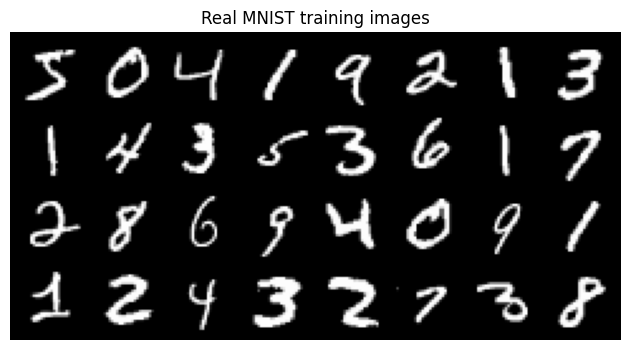

Training images: 60000


In [5]:
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
mnist = datasets.MNIST('data', train=True, download=True, transform=transform)
real_images = torch.stack([mnist[i][0] for i in range(32)])
grid = make_grid((real_images + 1) / 2, nrow=8)
plt.figure(figsize=(8, 4))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title('Real MNIST training images')
plt.axis('off')
plt.show()
print('Training images:', len(mnist))

## 6. Train the GAN
Each batch updates D using real images and detached fake images, then updates G to fool D. Adam uses a learning rate of 0.0002 and betas (0.5, 0.999). One grid and a checkpoint are saved after each epoch.

Do not treat GAN losses as classification accuracy. Inspect the digit shapes and variety in the images.

In [6]:
from train import run
trained_model = run(epochs=EPOCHS, batch_size=BATCH_SIZE,
                    output_dir=str(OUTPUT_DIR), resume=RESUME)
print('Training complete. Weights:', OUTPUT_DIR / 'generator.pt')

Training device: cuda
Epoch 1/20 | G: 2.2150 | D: 0.1901
Epoch 2/20 | G: 2.4448 | D: 0.1708
Epoch 3/20 | G: 2.4917 | D: 0.1839
Epoch 4/20 | G: 2.4594 | D: 0.1847
Epoch 5/20 | G: 2.4358 | D: 0.1974
Epoch 6/20 | G: 2.5233 | D: 0.1840
Epoch 7/20 | G: 2.5831 | D: 0.1824
Epoch 8/20 | G: 2.7029 | D: 0.1681
Epoch 9/20 | G: 2.7975 | D: 0.1628
Epoch 10/20 | G: 2.8146 | D: 0.1712
Epoch 11/20 | G: 2.9673 | D: 0.1461
Epoch 12/20 | G: 2.8559 | D: 0.1812
Epoch 13/20 | G: 3.0820 | D: 0.1377
Epoch 14/20 | G: 3.1250 | D: 0.1437
Epoch 15/20 | G: 3.0942 | D: 0.1578
Epoch 16/20 | G: 3.3088 | D: 0.1237
Epoch 17/20 | G: 3.3425 | D: 0.1282
Epoch 18/20 | G: 3.3080 | D: 0.1407
Epoch 19/20 | G: 3.4456 | D: 0.1154
Epoch 20/20 | G: 3.3563 | D: 0.1437
Training complete. Weights: /content/Assignment3_GAN_Yulin_Zhang_v2/outputs/generator.pt


## 7. Plot the losses and inspect image progression
The same noise vectors are used for the saved epoch grids. Compare early, middle, and final grids. GAN losses can fluctuate even when samples improve.

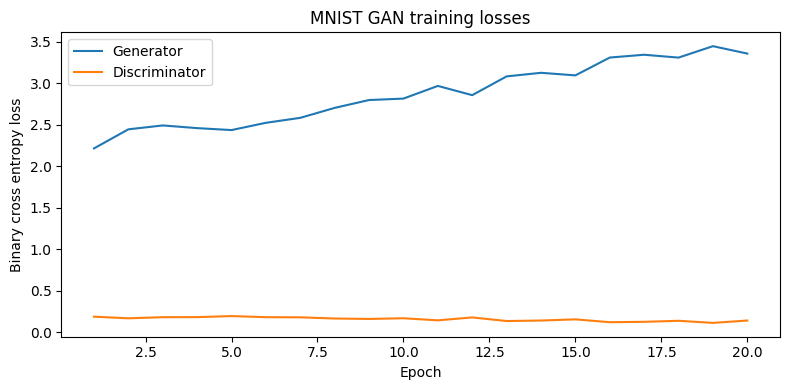

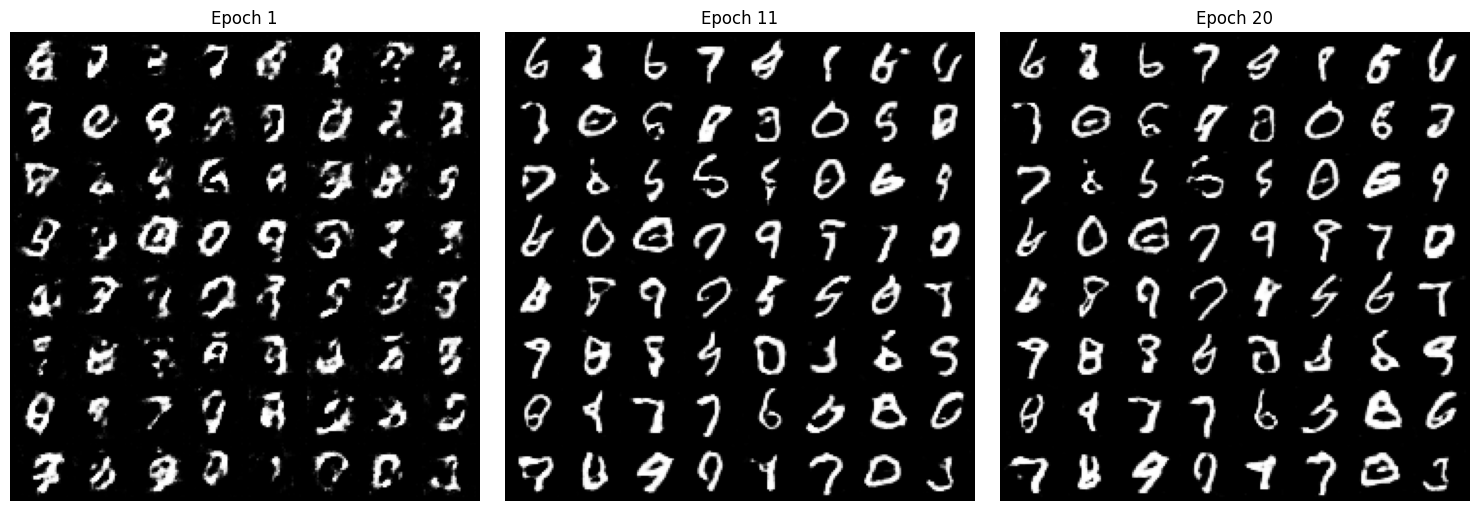

In [7]:
import csv
from PIL import Image

with (OUTPUT_DIR / 'loss_history.csv').open() as handle:
    history = list(csv.DictReader(handle))
epoch_numbers = [int(row['epoch']) for row in history]
plt.figure(figsize=(8, 4))
plt.plot(epoch_numbers, [float(row['generator_loss']) for row in history], label='Generator')
plt.plot(epoch_numbers, [float(row['discriminator_loss']) for row in history], label='Discriminator')
plt.xlabel('Epoch')
plt.ylabel('Binary cross entropy loss')
plt.title('MNIST GAN training losses')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'loss_plot.png', dpi=150)
plt.show()

chosen = sorted(set([epoch_numbers[0], epoch_numbers[len(epoch_numbers)//2], epoch_numbers[-1]]))
fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5), squeeze=False)
for axis, epoch in zip(axes[0], chosen):
    axis.imshow(Image.open(OUTPUT_DIR / f'epoch_{epoch:03d}.png'))
    axis.set_title(f'Epoch {epoch}')
    axis.axis('off')
plt.tight_layout()
plt.show()

## 8. Reload the saved generator and generate new samples
This confirms that the saved weights work independently of the training object. These are randomly generated digits; this unconditional model cannot request a specific digit class.

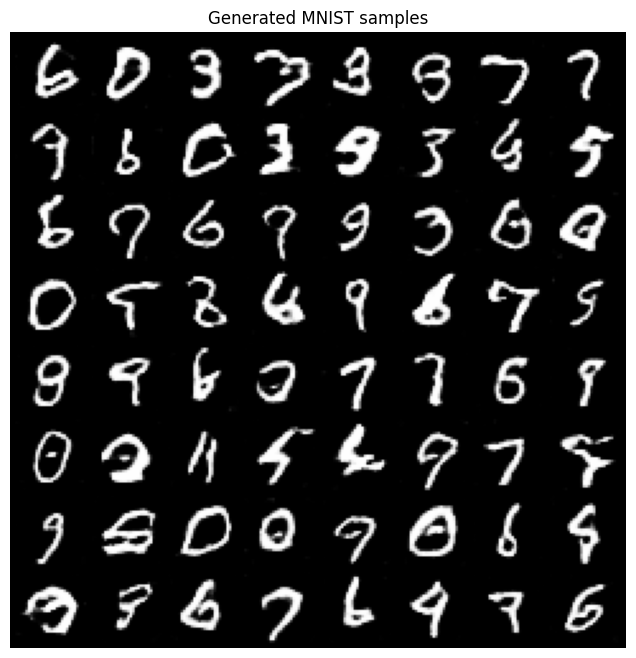

Generated batch: (64, 1, 28, 28)


In [8]:
from helper_lib.model import Generator
from helper_lib.generator import generate_samples

saved_generator = Generator()
saved_generator.load_state_dict(torch.load(OUTPUT_DIR / 'generator.pt', map_location='cpu', weights_only=True))
saved_generator.eval()
new_images = generate_samples(saved_generator, num_samples=64, seed=2026,
                              save_path=OUTPUT_DIR / 'final_samples.png', show=True)
print('Generated batch:', tuple(new_images.shape))

## 9. Test the FastAPI image endpoint
TestClient calls the real FastAPI routes in the notebook process. This verifies API integration without exposing a public server. Download the trained project and run uvicorn locally to use the browser Swagger page at `/docs`.

Health: {'status': 'ok', 'model_file_present': True}
Generate: 200 image/png
Invalid count: 422


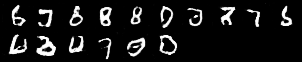

Local server command after downloading: python -m uvicorn api:app --port 8000


In [9]:
import io
from IPython.display import display
from fastapi.testclient import TestClient
import api

os.environ['GAN_MODEL_PATH'] = str(OUTPUT_DIR / 'generator.pt')
api.load_generator.cache_clear()
with TestClient(api.app) as client:
    health = client.get('/health')
    response = client.get('/generate', params={'num_samples': 16, 'seed': 42})
    invalid = client.get('/generate', params={'num_samples': 0})
    assert health.status_code == 200
    assert response.status_code == 200
    assert response.headers['content-type'] == 'image/png'
    assert invalid.status_code == 422
    repeated = client.get('/generate', params={'num_samples': 16, 'seed': 42})
    assert repeated.content == response.content
    print('Health:', health.json())
    print('Generate:', response.status_code, response.headers['content-type'])
    print('Invalid count:', invalid.status_code)
    display(Image.open(io.BytesIO(response.content)))
    (OUTPUT_DIR / 'api_generated.png').write_bytes(response.content)
    (OUTPUT_DIR / 'api_test_results.json').write_text(__import__('json').dumps({
        'health': health.json(), 'generation_status': response.status_code,
        'content_type': response.headers['content-type'],
        'invalid_count_status': invalid.status_code, 'same_seed_repeatable': True,
        'test_method': 'FastAPI TestClient with saved MNIST generator weights'
    }, indent=2))
print('Local server command after downloading: python -m uvicorn api:app --port 8000')

## 10. Theory answers

# Assignment 3: Building Blocks of GAN

Yulin Zhang

## Question 1

For dilation 1, the output size along each spatial dimension is:

O = (I - 1)S - 2P + K + OP

Substituting I = 8, K = 4, S = 2, P = 1, and OP = 1:

O = (8 - 1)(2) - 2(1) + 4 + 1 = 14 - 2 + 4 + 1 = 17.

Therefore, the output feature map is **17 x 17**.

## Question 2

Keeping the other values from Question 1, set S = 3:

O = (8 - 1)(3) - 2(1) + 4 + 1 = 21 - 2 + 4 + 1 = 24.

The output changes from **17 x 17 to 24 x 24**, an increase of 7 in each dimension. In general, increasing the stride by 1 increases each output dimension by I - 1, where I is that dimension's input size.

## Question 3

With dilation equal to 1:

**O = (I - 1)S - 2P + K + OP.**

Apply this formula separately to the height and width. I is input size, K is kernel size, S is stride, P is padding, and OP is output padding.

If dilation D is included, the general formula is:

O = (I - 1)S - 2P + D(K - 1) + OP + 1.

## Question 4

One possible configuration is **kernel size 2 x 2, stride 2, padding 0, output padding 0**, and dilation 1.

O = (16 - 1)(2) - 2(0) + 2 + 0 = 30 + 2 = 32.

Therefore, it upsamples a 16 x 16 feature map to **32 x 32**.

## Question 5

The mini-batch is [6, 8, 10, 6].

Mean:

mu = (6 + 8 + 10 + 6) / 4 = 7.5.

Batch variance (divide by 4):

variance = [(6 - 7.5)^2 + (8 - 7.5)^2 + (10 - 7.5)^2 + (6 - 7.5)^2] / 4

= (2.25 + 0.25 + 6.25 + 2.25) / 4 = 2.75.

Standard deviation = sqrt(2.75) = 1.6583.

Without gamma and beta, each normalized value is (x - mu) / sqrt(variance).

- 6: -1.5 / 1.6583 = -0.9045
- 8: 0.5 / 1.6583 = 0.3015
- 10: 2.5 / 1.6583 = 1.5076
- 6: -1.5 / 1.6583 = -0.9045

The normalized output is **[-0.9045, 0.3015, 1.5076, -0.9045]**.

This calculation ignores epsilon. Implementations use sqrt(variance + epsilon) for numerical stability; epsilon makes the variance of the normalized batch slightly less than 1. The normalization uses the biased batch variance, not the sample variance with denominator n - 1.

## Question 6

**ReLU(x) = max(0, x)**. Equivalently, ReLU(x) = x for x >= 0 and 0 for x < 0.

**LeakyReLU(x) = x for x >= 0, and alpha*x for x < 0**, where alpha is a small positive constant, such as 0.2 in this assignment.

The key difference is the negative-input slope: ReLU has slope 0, whereas LeakyReLU has slope alpha.

## Question 7

LeakyReLU allows a small gradient to pass through when the input is negative. With ReLU, the gradient is zero in that region, so some neurons may stop learning. LeakyReLU reduces this dying-ReLU problem and can help gradients flow through deep networks. It is often used in GAN discriminators. It does not guarantee stable GAN training or better results in every network.

## 11. Export the trained project and Docker deployment files
The ZIP includes the trained generator, sample grids, loss CSV/plot, summary, API test results, source code, Dockerfile, compose.yaml, live HTTP verification script, rubric checklist, and theory answers. Docker deployment is worth 20 points in the rubric. After downloading and extracting, run `docker compose up --build -d` in the final project folder, open `/docs`, and run `python verify_api.py`. Docker cannot be verified in this Colab notebook. It excludes the MNIST dataset and optimizer checkpoint to keep the GitHub upload small. Drive/local checkpoints remain available separately for resumption.

In Colab, the cell also attempts to save the current notebook with its displayed outputs. If that export is unavailable, use File > Download > Download .ipynb manually. The repository URL must be your actual GitHub URL; none is invented here.

In [ ]:
import json
import shutil
import zipfile

EXPORT = PROJECT.parent / 'Assignment3_GAN_Yulin_Zhang_Trained_v2'
EXPORT.mkdir(parents=True, exist_ok=True)
for name in PROJECT_FILES:
    source = PROJECT / name
    target = EXPORT / name
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, target)
export_outputs = EXPORT / 'outputs'
export_outputs.mkdir(exist_ok=True)
for source in OUTPUT_DIR.iterdir():
    if source.is_file() and source.name != 'training_checkpoint.pt':
        shutil.copy2(source, export_outputs / source.name)
try:
    from google.colab import _message
    notebook_data = _message.blocking_request('get_ipynb', timeout_sec=30)
    notebook = notebook_data['ipynb']
    if isinstance(notebook, str):
        notebook = json.loads(notebook)
    (EXPORT / 'Assignment3_GAN_Executed.ipynb').write_text(json.dumps(notebook), encoding='utf-8')
    print('Notebook with outputs saved.')
except Exception as error:
    print('Automatic notebook export unavailable. Use File > Download > Download .ipynb.')

zip_path = PROJECT.parent / 'Assignment3_GAN_Yulin_Zhang_Trained_v2.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for source in EXPORT.rglob('*'):
        if source.is_file():
            archive.write(source, Path(EXPORT.name) / source.relative_to(EXPORT))
print('Final project:', zip_path)
print('Before submitting: inspect the generated digits and upload the final code to GitHub.')
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Not in Colab; the ZIP is available at the path above.')